# Part 5: RBF support vector machine (SVM)

**Data used:** the 21 training people only, with the saved person-wise folds (`results/folds.csv`). The 9 test people are untouched.
**Main metric:** macro-F1 over the 7 folds. Baseline to beat: logistic regression, about 0.93 (Part 4).

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import PredefinedSplit, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from config import SEED, DATA

X = pd.read_csv(DATA + "/train/X_train.txt", sep=r"\s+", header=None).values
y = np.loadtxt(DATA + "/train/y_train.txt", dtype=int)
groups = np.loadtxt(DATA + "/train/subject_train.txt", dtype=int)

folds_table = pd.read_csv("results/folds.csv", index_col="person")["fold"]
fold_of_window = folds_table.loc[groups].values
saved_folds = PredefinedSplit(fold_of_window)

print(X.shape, fold_of_window.shape, saved_folds.get_n_splits())

(7352, 561) (7352,) 7


## How an RBF SVM predicts
- Logistic regression draws **flat** boundaries between activities. The RBF SVM can draw **curved** ones.
- It keeps a set of training windows called **support vectors** (the hard cases near the boundaries). To score a new window, it measures how **similar** the window is to each support vector: `k(x, x') = exp(-gamma × ||x - x'||²)`. The score is a weighted sum of these similarities.
- **gamma** = how far one training window's influence reaches. Small gamma: each window influences a wide area, so the boundary is smooth (close to linear). Large gamma: each window only affects its close neighbours, so the boundary can wiggle around single points (risk of overfitting).
- **C** = how much a training mistake costs. Small C: the model accepts some training mistakes to keep a wide, simple margin. Large C: it tries hard to classify every training window correctly (risk of overfitting).
- With 6 activities, scikit-learn trains one SVM per **pair** of activities (15 pairs) and takes a vote.
- **Scaling matters:** the similarity uses distances, so a feature with a big range would dominate. `StandardScaler` goes first, inside the pipeline, so it is learned from each fold's training people only.

In [2]:
train_rows = fold_of_window != 0
val_rows = fold_of_window == 0

start = time.time()
model = make_pipeline(StandardScaler(), SVC(kernel="rbf"))   # defaults: C=1, gamma="scale"
model.fit(X[train_rows], y[train_rows])
print("fit time (s):", round(time.time() - start, 1))

from sklearn.metrics import f1_score
pred = model.predict(X[val_rows])
print("fold 0 macro-F1:", round(f1_score(y[val_rows], pred, average="macro"), 3))

svm = model[-1]
print("support vectors:", svm.n_support_.sum(), "of", train_rows.sum(), "training windows")
print("per activity:", svm.n_support_)

# gamma="scale" means 1 / (number of features x variance of the inputs).
# After StandardScaler every feature has variance 1, so this is 1/561.
print("gamma='scale' here =", round(1 / (X.shape[1] * 1.0), 5))

# How far apart are two windows after scaling? (500 random pairs of training windows)
Z = model[0].transform(X[train_rows])
rng = np.random.default_rng(SEED)
a, b = rng.integers(0, len(Z), 500), rng.integers(0, len(Z), 500)
dist2 = ((Z[a] - Z[b]) ** 2).sum(axis=1)
print("median squared distance between two windows:", round(np.median(dist2)))
for gamma in [1e-3, 1e-2, 1e-1]:
    print("  similarity exp(-gamma x distance²) with gamma =", gamma, ":", f"{np.exp(-gamma * np.median(dist2)):.2g}")

fit time (s): 1.9


fold 0 macro-F1: 0.91
support vectors: 2133 of 6294 training windows
per activity: [266 311 324 538 493 201]
gamma='scale' here = 0.00178
median squared distance between two windows: 872
  similarity exp(-gamma x distance²) with gamma = 0.001 : 0.42
  similarity exp(-gamma x distance²) with gamma = 0.01 : 0.00016
  similarity exp(-gamma x distance²) with gamma = 0.1 : 1.4e-38


## Tuning C and gamma on the saved folds
Grid: C in {0.1, 1, 10, 100, 1000} × gamma in {1e-4, 1e-3, "scale" (= 1/561 ≈ 0.0018), 1e-2, 1e-1} = 25 settings × 7 folds = 175 fits.

⚠️ **Slow cell: about 12–30 minutes** on a 12-core laptop CPU (12.5 min when nothing else was running; one fit takes a few seconds up to about 50 s, and large C and large gamma are the slowest). Each setting runs its 7 folds in parallel (`n_jobs=-1`). The results are saved in `results/cv_svm.csv`, so later notebooks do not need to rerun this.

In [3]:
C_values = [0.1, 1, 10, 100, 1000]
gamma_values = [1e-4, 1e-3, "scale", 1e-2, 1e-1]
rows = []

start = time.time()
for C in C_values:
    for gamma in gamma_values:
        model = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=C, gamma=gamma))
        f1s = cross_val_score(model, X, y, cv=saved_folds, scoring="f1_macro", n_jobs=-1)
        setting = "C=" + str(C) + " gamma=" + str(gamma)
        for fold in range(7):
            rows.append({"model": "svm_rbf", "setting": setting, "fold": fold, "macro_f1": f1s[fold]})
        print(setting.ljust(24), " mean", round(f1s.mean(), 3), " spread", round(f1s.std(), 3))

cv_svm = pd.DataFrame(rows)
print("total time (min):", round((time.time() - start) / 60, 1))

C=0.1 gamma=0.0001        mean 0.719  spread 0.034


C=0.1 gamma=0.001         mean 0.895  spread 0.024


C=0.1 gamma=scale         mean 0.89  spread 0.028


C=0.1 gamma=0.01          mean 0.758  spread 0.044


C=0.1 gamma=0.1           mean 0.054  spread 0.003


C=1 gamma=0.0001          mean 0.908  spread 0.025


... (15 outputs left out)

C=1000 gamma=0.001        mean 0.934  spread 0.022


C=1000 gamma=scale        mean 0.931  spread 0.022


C=1000 gamma=0.01         mean 0.847  spread 0.044


C=1000 gamma=0.1          mean 0.062  spread 0.016
total time (min): 12.5


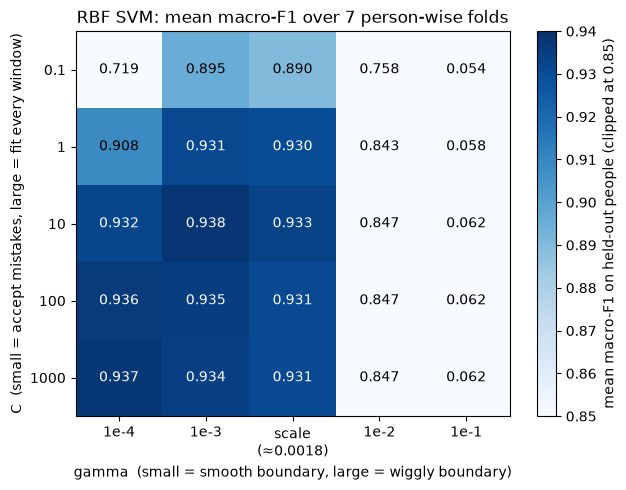

gamma   0.0001  0.001  scale   0.01    0.1
C                                         
0.1      0.719  0.895  0.890  0.758  0.054
1.0      0.908  0.931  0.930  0.843  0.058
10.0     0.932  0.938  0.933  0.847  0.062
100.0    0.936  0.935  0.931  0.847  0.062
1000.0   0.937  0.934  0.931  0.847  0.062


In [4]:
summary = cv_svm.groupby("setting", sort=False)["macro_f1"].agg(["mean", "std"])
summary["se"] = summary["std"] / np.sqrt(7)
summary["C"] = [C for C in C_values for g in gamma_values]
summary["gamma"] = [g for C in C_values for g in gamma_values]

grid = summary.pivot(index="C", columns="gamma", values="mean")[gamma_values]

# The colour scale starts at 0.85 so that the differences between the good settings are visible;
# every cell below 0.85 is drawn in the lightest colour (its number is still printed).
plt.figure(figsize=(7, 5))
plt.imshow(grid.values, cmap="Blues", aspect="auto", vmin=0.85, vmax=0.94)
plt.colorbar(label="mean macro-F1 on held-out people (clipped at 0.85)")
for i in range(len(C_values)):
    for j in range(len(gamma_values)):
        value = grid.values[i, j]
        plt.text(j, i, f"{value:.3f}", ha="center", va="center",
                 color="white" if value > 0.915 else "black")
plt.xticks(range(len(gamma_values)), ["1e-4", "1e-3", "scale\n(≈0.0018)", "1e-2", "1e-1"])
plt.yticks(range(len(C_values)), C_values)
plt.xlabel("gamma  (small = smooth boundary, large = wiggly boundary)")
plt.ylabel("C  (small = accept mistakes, large = fit every window)")
plt.title("RBF SVM: mean macro-F1 over 7 person-wise folds")
plt.show()

print(grid.round(3))

## Choosing a setting: the one-standard-error rule
Same rule as Part 4: SE = std over the 7 folds ÷ √7. The threshold is (best mean − best SE). Among the settings above the threshold, pick the **simplest**.

**Simplest for the SVM** = smallest C first (more tolerant of training mistakes, wider margin), then smallest gamma (smoother boundary). Both make the model less able to bend around individual training windows.

In [5]:
best_setting = summary["mean"].idxmax()
threshold = summary.loc[best_setting, "mean"] - summary.loc[best_setting, "se"]
print("best:", best_setting, " mean", round(summary.loc[best_setting, "mean"], 4),
      " SE", round(summary.loc[best_setting, "se"], 4), " threshold:", round(threshold, 4))

gamma_number = {1e-4: 1e-4, 1e-3: 1e-3, "scale": 1 / 561, 1e-2: 1e-2, 1e-1: 1e-1}
summary["gamma_number"] = summary["gamma"].map(gamma_number)

within = summary[summary["mean"] >= threshold].sort_values(["C", "gamma_number"])
print()
print("settings within one SE of the best (simplest first):")
print(within[["mean", "std", "se"]].round(4))

chosen = within.index[0]
print()
print("chosen (simplest within one SE):", chosen)

# Is the best on the edge of the grid? If so, the grid should be extended.
best_C, best_gamma = summary.loc[best_setting, "C"], summary.loc[best_setting, "gamma"]
print("best C on an edge:", best_C in [C_values[0], C_values[-1]],
      "| best gamma on an edge:", best_gamma in [gamma_values[0], gamma_values[-1]])

best: C=10 gamma=0.001  mean 0.9377  SE 0.0095  threshold: 0.9283

settings within one SE of the best (simplest first):
                       mean     std      se
setting                                    
C=1 gamma=0.001      0.9313  0.0266  0.0101
C=1 gamma=scale      0.9301  0.0269  0.0102
C=10 gamma=0.0001    0.9321  0.0334  0.0126
C=10 gamma=0.001     0.9377  0.0251  0.0095
C=10 gamma=scale     0.9333  0.0246  0.0093
C=100 gamma=0.0001   0.9360  0.0319  0.0120
C=100 gamma=0.001    0.9348  0.0234  0.0088
C=100 gamma=scale    0.9312  0.0235  0.0089
C=1000 gamma=0.0001  0.9374  0.0269  0.0102
C=1000 gamma=0.001   0.9343  0.0238  0.0090
C=1000 gamma=scale   0.9312  0.0235  0.0089

chosen (simplest within one SE): C=1 gamma=0.001
best C on an edge: False | best gamma on an edge: False


## Comparison with logistic regression (same folds, same people)
Because both models are scored on exactly the same 7 folds, we can compare them **fold by fold**. This is fairer than comparing two means, because the hard folds are hard for every model.

In [6]:
cv_logistic = pd.read_csv("results/cv_logistic.csv")

def fold_scores(table, model_name, setting):
    part = table[(table["model"] == model_name) & (table["setting"] == setting)]
    return part.sort_values("fold")["macro_f1"].values

compare = pd.DataFrame({
    "logistic ridge C=0.01": fold_scores(cv_logistic, "logistic_L2", "C=0.01"),
    "logistic lasso C=0.1": fold_scores(cv_logistic, "logistic_L1", "C=0.1"),
    "SVM " + chosen: fold_scores(cv_svm, "svm_rbf", chosen),
    "SVM best " + best_setting: fold_scores(cv_svm, "svm_rbf", best_setting),
}, index=pd.Index(range(7), name="fold"))
compare["people"] = [sorted(folds_table[folds_table == f].index.tolist()) for f in range(7)]

print(compare.round(3))
print()
print(compare.drop(columns="people").agg(["mean", "std"]).round(3))

diff = compare["SVM " + chosen] - compare["logistic lasso C=0.1"]
print()
print("SVM (chosen) minus lasso, per fold:", diff.round(3).values)
print("SVM better on", (diff > 0).sum(), "of 7 folds; mean difference", round(diff.mean(), 4))

      logistic ridge C=0.01  logistic lasso C=0.1  SVM C=1 gamma=0.001  \
fold                                                                     
0                     0.920                 0.920                0.915   
1                     0.952                 0.965                0.950   
2                     0.872                 0.882                0.893   
3                     0.957                 0.963                0.955   
4                     0.890                 0.917                0.910   
5                     0.922                 0.909                0.931   
6                     0.983                 0.982                0.964   

      SVM best C=10 gamma=0.001        people  
fold                                           
0                         0.929  [15, 22, 25]  
1                         0.950    [3, 8, 21]  
2                         0.907  [14, 26, 29]  
3                         0.960    [1, 6, 30]  
4                         0.917   [7, 19, 28]

In [7]:
cv_svm.to_csv("results/cv_svm.csv", index=False)

check = pd.read_csv("results/cv_svm.csv")
print("columns:", list(check.columns), "| same as cv_logistic:", list(check.columns) == list(cv_logistic.columns))
print("rows:", len(check), "| settings:", check["setting"].nunique(),
      "| rows per setting:", check.groupby("setting").size().unique())
print("missing values:", check.isna().sum().sum(), "| folds:", sorted(check["fold"].unique()))

columns: ['model', 'setting', 'fold', 'macro_f1'] | same as cv_logistic: True
rows: 175 | settings: 25 | rows per setting: [7]
missing values: 0 | folds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


# Part 5 summary: RBF SVM

**Data used:** the 21 training people only, with the saved person-wise folds. The 9 test people are untouched.

## Cell by cell
**Cell 1: load.** X (7352 × 561), y, groups; the saved folds loaded with `PredefinedSplit`, exactly as in Part 4.

**Cell 2: one SVM with the default settings (C = 1, gamma = "scale") on fold 0.** Fit in a few seconds; macro-F1 **0.910** on people 15, 22, 25. It keeps **2,133 of 6,294** training windows as support vectors, most of them for **sitting (538) and standing (493)**: the hardest pair needs the most "boundary examples". gamma = "scale" works out to 1/561 ≈ 0.0018, because the scaler gives every feature variance 1.

**Cells 3–4: the grid (25 settings × 7 folds = 175 fits, 12.5 min).**

| C \ gamma | 1e-4 | 1e-3 | scale (≈0.0018) | 1e-2 | 1e-1 |
|---|---|---|---|---|---|
| 0.1 | 0.719 | 0.895 | 0.890 | 0.758 | 0.054 |
| 1 | 0.908 | **0.931** | 0.930 | 0.843 | 0.058 |
| 10 | 0.932 | **0.938** (best) | 0.933 | 0.847 | 0.062 |
| 100 | 0.936 | 0.935 | 0.931 | 0.847 | 0.062 |
| 1000 | 0.937 | 0.934 | 0.931 | 0.847 | 0.062 |

What the grid shows:
- **gamma matters much more than C.** The good band is gamma = 1e-4 to "scale". From gamma = 1e-2 the score falls, and at **gamma = 0.1 the model collapses to ≈ 0.06, the same as always predicting one class.** Reason (Cell 2): with 561 standardised features, two windows are far apart (median squared distance **872**), so the similarity `exp(-gamma × distance²)` is 0.42 for gamma = 0.001 but **1.4e-38** for gamma = 0.1, practically 0. Every window is "similar" only to itself, so a new person's window is similar to nothing and gets the same score for every activity.
- **Small C with small gamma underfits** (C = 0.1, gamma = 1e-4: 0.719): the boundary is too smooth and mistakes are too cheap.
- From C = 10 upwards the row barely changes: the model already fits the training windows, so a bigger C changes nothing.
- The best (C = 10, gamma = 0.001) is **not on the edge** of the grid, so the grid did not need extending. The near-best corner (C = 1000, gamma = 1e-4: 0.937) is on the edge, but it scores the same as the best, and larger C would only make the model more complex, so it cannot change the one-SE choice.

**Cell 5: one-SE rule.** Best = C = 10, gamma = 0.001: 0.9377, SE = 0.0095 → threshold **0.9283**. Eleven settings are within one SE. **Simplest = smallest C, then smallest gamma** → **C = 1, gamma = 0.001** (0.931 ± 0.027 std, SE 0.010).
- Why that order: a smaller C allows more training mistakes (wider margin), and a smaller gamma gives a smoother boundary. Both make the model less able to bend around single training windows. We put C first, as agreed for the project. (C = 10 with gamma = 1e-4 is also within one SE and arguably as simple; it scores about the same, 0.932, so the choice does not matter in practice.)
- Caveat (same as Part 4): every setting is tested on the same people, so this SE is cautious.

**Cell 6: comparison with logistic regression (fold by fold).**

| Fold (people) | Ridge C=0.01 | Lasso C=0.1 | SVM C=1 γ=0.001 (chosen) | SVM C=10 γ=0.001 (best) |
|---|---|---|---|---|
| 0 (15, 22, 25) | 0.920 | 0.920 | 0.915 | 0.929 |
| 1 (3, 8, 21) | 0.952 | 0.965 | 0.950 | 0.950 |
| 2 (14, 26, 29) | 0.872 | 0.882 | 0.893 | 0.907 |
| 3 (1, 6, 30) | 0.957 | 0.963 | 0.955 | 0.960 |
| 4 (7, 19, 28) | 0.890 | 0.917 | 0.910 | 0.917 |
| 5 (5, 16, 27) | 0.922 | 0.909 | 0.931 | 0.925 |
| 6 (11, 17, 23) | 0.983 | 0.982 | 0.964 | 0.976 |
| **mean ± std** | 0.928 ± 0.039 | 0.934 ± 0.036 | 0.931 ± 0.027 | 0.938 ± 0.025 |

- The chosen SVM and lasso are **tied**: the SVM is better on 2 of 7 folds, and the mean difference is −0.003, far smaller than the differences between folds.
- The SVM's spread over people is a bit **smaller** (std 0.027 vs 0.036): it does better on the hardest people (fold 2: 0.893 vs 0.882) and slightly worse on the easiest (fold 6).
- So curved boundaries give **little extra** over flat ones here. The 561 hand-made features already make the activities almost linearly separable, and the remaining errors come from differences between people, not from the shape of the boundary.

**Cell 7: saved** all 175 fold scores to `results/cv_svm.csv` (same 4 columns as `cv_logistic.csv`, 7 rows per setting, no missing values, folds 0–6).

## Decision carried to Part 7
- **SVM candidate: C = 1, gamma = 0.001** (macro-F1 **0.931 ± 0.027** std, SE 0.010), chosen by the one-SE rule as the simplest setting within one SE of the best.
- The best-scoring setting (C = 10, gamma = 0.001, 0.938 ± 0.025) is within noise of it.

## Five takeaways
1. An RBF SVM scores a window by its similarity to stored "boundary" windows (support vectors). gamma sets how local the similarity is, and C sets how costly training mistakes are.
2. **gamma is the setting that matters**: too large (0.1), and the model knows nothing about new people (macro-F1 0.06).
3. Many settings tie within one SE; the simplest is **C = 1, gamma = 0.001**.
4. The SVM is **tied with logistic regression** (0.931 vs 0.934) and a little more consistent across people.
5. As in Part 4, **which people are in the fold matters more than the model's settings** (fold scores 0.893–0.964).